# 20.2 Attention Intuition

The key idea of **attention** is to remove the fixed-context bottleneck from vanilla Seq2Seq.

Instead of forcing the encoder to compress the entire sentence into **one vector**, the decoder can access the **sequence of encoder hidden states** and decide which ones are important at each decoding step.

---

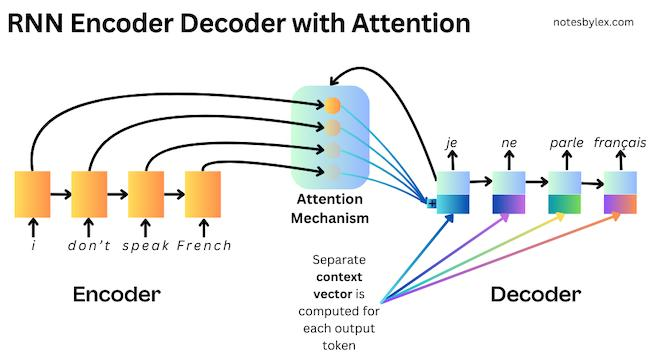
## 1. Vanilla Seq2Seq

Without attention:
```
Input sentence
     │
     ▼
┌───────────┐
│  Encoder  │
└───────────┘
     │
     ▼
 ┌────────┐
 │   c    │  ← one fixed context vector
 └────────┘
     │
     ▼
┌───────────┐
│  Decoder  │
└───────────┘
     │
     ▼
Output sentence
```

The decoder receives one compressed representation:

$$
\mathbf{c}
$$

regardless of which output token it is currently generating.

---

# 2. Attention-Based Seq2Seq

With attention, the encoder keeps its **hidden states**:

$$
\mathbf{h}_1,\mathbf{h}_2,\ldots,\mathbf{h}_T
$$

Instead of throwing these away and keeping only one final representation, the decoder can inspect them.
```
Input tokens
   │
   ▼
Encoder
   │
   ├── h₁
   ├── h₂
   ├── h₃
   ├── ...
   └── hₜ
          │
          ▼
     ┌──────────┐
     │ Attention│
     └──────────┘
          ▲
          │
       Decoder
          │
          ▼
    current output
```

The decoder essentially asks:

> **"Which encoder states are relevant for generating my next token?"**

---

# 3. The Decoder "Looks" at the Input

Suppose we are translating:

> **"The cat eats fish."**

and the decoder is generating the equivalent of **"chat"**.

The decoder may assign higher importance to the encoder state corresponding to:
```
The    cat    eats    fish
 ↓      ↓       ↓       ↓
0.05   0.80    0.10    0.05
```

These values are **attention weights**.

So instead of treating every encoder state equally, the decoder focuses more strongly on the relevant information.

---

# 4. Constructing the Context Vector

This is the central intuition.

At decoder step $t$, attention computes weights:

$$
\alpha_{t,1},\alpha_{t,2},\ldots,\alpha_{t,T}
$$

for the encoder states.

The context vector becomes a **weighted combination**:

$$
\boxed{
\mathbf{c}_t = \sum_{i=1}^{T} \alpha_{t,i}\mathbf{h}_i
}
$$

Notice the important difference:

### Vanilla Seq2Seq

$$
\boxed{\mathbf{c}}
$$

One fixed context vector.

### Attention

$$
\boxed{\mathbf{c}_1,\mathbf{c}_2,\mathbf{c}_3,\ldots}
$$

A potentially **different context vector at every decoding step**.

---

# 5. Why This Is Powerful

Suppose the decoder is generating three different output tokens:
```
                 Encoder states
              h₁   h₂   h₃   h₄
              │    │    │    │
              ▼    ▼    ▼    ▼

Decoder step 1:  ████░░░░
Decoder step 2:  ░░████░░
Decoder step 3:  ░░░░████
```

The attention distribution can change depending on what the decoder currently needs.

So:

$$
\boxed{
\text{Attention is dynamic information retrieval}
}
$$

The decoder doesn't have to rely on a single compressed memory.

---

# 6. The Most Important Concept

Compare these two architectures:

### Vanilla Seq2Seq
```
Input
  ↓
Encoder
  ↓
ONE fixed vector
  ↓
Decoder
  ↓
Output
```

### Attention-based Seq2Seq
```
Input
  ↓
Encoder
  ↓
ALL encoder states
  ↓
Attention ← Decoder state
  ↓
Relevant weighted information
  ↓
Context vector
  ↓
Decoder
  ↓
Output
```

The second approach gives the decoder **direct access to information distributed across the input sequence**.

---

## 🔗 Connection to Your Existing DL Knowledge

You already know the basic idea of **self-attention** from your Deep Learning syllabus.

Here, the important NLP-specific perspective is:

> **Attention originally provides a mechanism for the decoder to selectively access encoder representations during sequence generation.**

This is commonly called **cross-attention** in Transformer terminology because the query comes from one sequence/component and the keys/values come from another.

We'll formalize that later.

---

## ⭐ Must Know

$$
\boxed{
\text{Attention} = \text{weighted retrieval of relevant encoder information}
}
$$

At each decoder step:

$$
\boxed{
\mathbf{c}_t = \sum_i \alpha_{t,i}\mathbf{h}_i
}
$$

where:

- $\mathbf{h}_i$ = encoder hidden state for input position $i$
- $\alpha_{t,i}$ = how much attention the decoder gives to position $i$
- $\mathbf{c}_t$ = context vector for decoder step $t$

**The key improvement:** the context is **dynamic**, not fixed.

### What you should remember

1. Attention removes the **single fixed context-vector bottleneck**.
2. The encoder provides **multiple hidden states**.
3. The decoder determines which encoder states are relevant.
4. Attention weights represent the importance of different input positions.
5. A new context vector can be constructed at **each decoding step**.
6. This idea leads naturally to **Q, K, V and cross-attention**.

---